In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/7/2022
# version ='1.0'

### Demo: A minimization of a log-barrier function, $f(x)=c^T x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$, with $m=n=2$

In the text book {book-convex-2004}, section 9.3, gradient descent method, the author has discussed a problem in the form of  $f(x)=c^T x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$, for m=500 and n=100. 

However, it is hard to visualize the characteristics of function $f(x)$ because of the high dimensionality. In this demo, the special scenario for m=2, n=2 is discussed and the visualization for the characteristics of $f(x)$ is provided. 

The objective function for minimization, $f(x), x\in R^2$, is $f(x)=c^T x -\displaystyle{\sum_{i=1}^{2}}\log(b_i-a_i^Tx)$. By letting $\Delta f(x)=0$, it leads to
$$
c = - \frac{a_1}{b_1-a_1^Tx_p} - \frac{a_2}{b_2-a_2^Tx_p} 
$$
i.e. $c$ is a linear combination of $a_1$ and $a_2$ with coefficients $\lambda_1, \lambda_2$ being not equal to 0, or 
$$
\begin{array}{rcl}
Ax_p & = & b-\left[\begin{array}{c}
\frac{1}{\lambda_1} \\
\frac{1}{\lambda_2}
\end{array} \right]
\end{array}
$$
If to make $f(x)$ reach the its minimal at $x_p=\bar{0}$, $b$, then $b$ can be selected to be $\left[\begin{array}{c}
\frac{1}{\lambda_1} \\
\frac{1}{\lambda_2}
\end{array} \right]$, and $A$ should be selected to have $rank(A)=2$.

In this experiment, $A=\left[\begin{array}{cc}
1 & 1 \\
1 & 2 \\
\end{array}\right]$, $c=\left[\begin{array}{c}
-3 \\ 
-5 \\
\end{array} \right]$, and $b=\left[\begin{array}{c}
1 \\
0.5 \\
\end{array} \right]$. 

Moreover, two initializations of $t$ (denoted as $t_0$), in the backtracking line search method are simulated: $t_0=1$ and  $t_0=100$.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).







In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

The log barrier function $f(x)=c^T x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$

The derivative of the log barrier function, $\nabla f(x)=c+\displaystyle{\sum_{i=1}^{m}}\dfrac{A^T}{b_i-a_i^Tx}$


x should satisfy that: $b-Ax\succeq 0$

In [3]:
def my_f_fesasible(x, c, b, A):
    """
    x should satisfy that: $b-Ax\succeq 0$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return np.all(b - A @ x > 0)


def my_f(x, c, b, A):
    """
    the log barrier function $f(x)=c^T x -\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^Tx)$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return (c.T @ x - np.sum(np.log(b - A @ x))).item()


def my_derivative_f(x, c, b, A):
    """
    the derivative of the log barrier function, $\nabla f(x)=c+\displaystyle{\sum_{i=1}^{m}}\dfrac{A^T}{b_i-a_i^Tx}$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return c + np.sum(A.T @ (1 / (b - A @ x)), axis=1).reshape((-1, 1))

The backtracking line search method

In [4]:
def backtracking_line_search(t0, f, df, x, delta_x, alpha, beta, args):
    """
    the backtracking line search method
    :param t0:
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = t0
    while (not my_f_fesasible(x + delta_x * t, *args)) or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * (
            df(x, *args).T @ delta_x).item():
        t = beta * t
    return t

Plot the convergence of the x during the gradient method

In [5]:
def plot_log_barrier_m2n2_convergence():
    """
    plot the convergence of the x during the gradient method
    :return:
    """
    np.random.seed(1)
    m = 2
    n = 2
    c = -1 * np.array([[3], [5]])
    b = np.array([[1], [0.5]])
    A = np.array([[1, 1], [1, 2]])
    args = (c, b, A)
    min_x1 = -3
    max_x1 = +3
    min_x2 = -3
    max_x2 = +3
    delta = 0.01
    x = np.arange(min_x1, max_x1, delta)
    y = np.arange(min_x2, max_x2, delta)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros(X.shape)

    for x1_i in range(len(x)):
        for x2_i in range(len(y)):
            x1 = x[x1_i]
            x2 = y[x2_i]
            Z[x2_i][x1_i] = my_f(np.array([[x1, x2]]).T, *args)

    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 3, 1)
    levels = np.arange(-1, 5, 0.25)
    CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=2)
    ax.clabel(CS, fontsize=6, inline=True)
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_title(r'$f(x)$')

    alpha = 0.1
    beta = 0.5
    x0 = np.array([[-2, 1]]).T
    num_iter = 200
    x = x0
    delta_x = -1 * my_derivative_f(x0, *args)
    x_points = np.zeros([num_iter, 2])
    fx = np.zeros([num_iter, 1])
    t0 = 1
    for iter in range(num_iter):
        x_points[iter] = np.squeeze(x)
        fx[iter] = my_f(x, *args)
        t = backtracking_line_search(t0, my_f, my_derivative_f, x, delta_x, alpha, beta, args)
        x_next = x + t * delta_x

        x = x_next
        delta_x = -1 * my_derivative_f(x_next, *args)

    ax.plot(x_points[:, 0], x_points[:, 1], marker='+', color='black', label=r'backtracking ($t_0$=1)')

    x = np.arange(min_x1, max_x1, delta)
    y = np.array([(b[0] - A[0][0] * t) / A[0][1] for t in x])
    ax.plot(x, y, linestyle='dashed', label=r'$a_1^T x = b1$')

    x = np.arange(min_x1, max_x1, delta)
    y = np.array([(b[1] - A[1][0] * t) / A[1][1] for t in x])
    ax.plot(x, y, linestyle='dashed', label=r'$a_2^T x = b2$')
    ax.grid()
    ax.legend()

    ax = plt.subplot(1, 3, 2)

    f_min = -math.log(b[0]) - math.log(b[1])
    ax.semilogy(np.arange(0, num_iter), fx - f_min, marker='+', fillstyle='none', label=r'backtracking ($t_0$=1)')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.set_xlabel('k')
    ax.set_ylabel(r'$f(x^k)-p^*$')
    ax.grid()
    ax.legend()

    ax = plt.subplot(1, 3, 3)
    levels = np.arange(-1, 5, 0.25)
    CS = ax.contour(X, Y, Z, linestyles='dashed', levels=levels, vmin=0, vmax=2)
    ax.clabel(CS, fontsize=6, inline=True)
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_title(r'$f(x)$')

    alpha = 0.1
    beta = 0.5
    x0 = np.array([[-2, 1]]).T
    num_iter = 200
    x = x0
    delta_x = -1 * my_derivative_f(x0, *args)
    x_points = np.zeros([num_iter, 2])
    fx = np.zeros([num_iter, 1])
    t0 = 100
    for iter in range(num_iter):
        x_points[iter] = np.squeeze(x)
        fx[iter] = my_f(x, *args)
        t = backtracking_line_search(t0, my_f, my_derivative_f, x, delta_x, alpha, beta, args)
        x_next = x + t * delta_x

        x = x_next
        delta_x = -1 * my_derivative_f(x_next, *args)

    ax.plot(x_points[:, 0], x_points[:, 1], marker='+', color='black', label=r'backtracking ($t_0$=100)')

    x = np.arange(min_x1, max_x1, delta)
    y = np.array([(b[0] - A[0][0] * t) / A[0][1] for t in x])
    ax.plot(x, y, linestyle='dashed', label=r'$a_1^T x = b1$')

    x = np.arange(min_x1, max_x1, delta)
    y = np.array([(b[1] - A[1][0] * t) / A[1][1] for t in x])
    ax.plot(x, y, linestyle='dashed', label=r'$a_2^T x = b2$')
    ax.grid()
    ax.legend()

    ax = plt.subplot(1, 3, 2)
    f_min = -math.log(b[0]) - math.log(b[1])
    ax.semilogy(np.arange(0, num_iter), fx - f_min, marker='+', fillstyle='none', label=r'backtracking ($t_0$=100)')
    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.set_xlabel('k')
    ax.set_ylabel(r'$f(x^k)-p^*$')
    ax.legend()
    plt.show()

C:\Users\Edwin\AppData\Local\Temp/ipykernel_24036/3051547342.py:22: RuntimeWarning: invalid value encountered in log
  return (c.T @ x - np.sum(np.log(b - A @ x))).item()


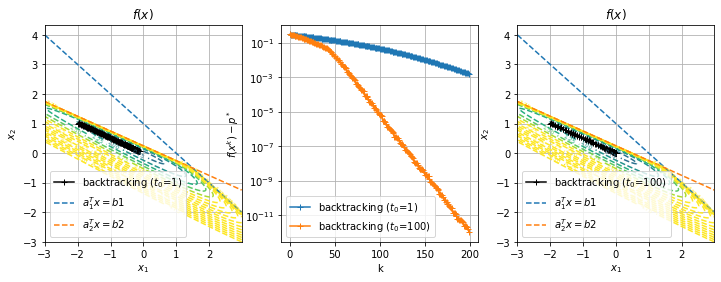

In [6]:
if __name__ == "__main__":
    plot_log_barrier_m2n2_convergence()